In [118]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Chart of values: This part of the notebook is for troubleshooting and graphical analysis.

In [119]:
#raw_fuel_data=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\Export.csv',sep=';',encoding='latin1')
raw_fuel_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\trans_posada\CCJ-738.xlsx')
raw_fuel_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 42702 entries, 0 to 42701
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  42702 non-null  str  
 1   Message  42702 non-null  str  
 2   Status   42702 non-null  str  
dtypes: str(3)
memory usage: 1001.0 KB


In [120]:
e0x=raw_fuel_data[raw_fuel_data['Status'].str.contains('0x252521')]
row_number=e0x.shape[0]
#e0x.to_csv('/home/jlhb1984/py-projects/data/veepo/wcr728_.csv')

In [121]:
fs01_dec_value=[]
fs02_dec_value=[]
last_index_fs01=[]
last_index_fs02=[]
date_fs01_dec_value=[]
date_fs02_dec_value=[]
fs01_raw_data=[]
fs02_raw_data=[]
values_dates_fs01=pd.DataFrame()
values_dates_fs02=pd.DataFrame()

for i in range(0,row_number):
    e0x_aux=e0x.iloc[i,2]
    e0x_fs01_aux='xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx'+e0x_aux[32:]
    aux=e0x_fs01_aux.find('3E01')
    if ((aux>47) & (aux<49)):
        fs01=(e0x_aux[48:66])
        #print(fs01,e0x.iloc[i,2])
        if len(fs01)>17:
            msb=fs01[10:12]
            lsb=fs01[8:10]
            measure=msb+lsb
            fs01_dec_value.append(int(measure,16))
            date_fs01_dec_value.append(e0x.iloc[i,2][32:44])
            last_index_fs01=i
            fs01_raw_data.append(e0x_aux)
            
#print(i, raw_data.iloc[i,0] )

for i in range(0,row_number):
    e0x_aux=e0x.iloc[i,2]
    e0x_fs02_aux='xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx'+e0x_aux[32:]
    aux=e0x_fs02_aux.find('3E02')    
    if ((aux>47) & (aux<49)):
        fs02=e0x_aux[48:66]
        #print(fs02,aux)
        if len(fs02)>17:
            msb=fs02[10:12]
            lsb=fs02[8:10]
            measure=msb+lsb
            fs02_dec_value.append(int(measure,16))
            date_fs02_dec_value.append(e0x.iloc[i,2][32:44])
            last_index_fs02=i
            fs02_raw_data.append(e0x_aux)
            
        #print(fs01_cad)   

fs01_count=len(fs01_dec_value)
fs02_count=len(fs02_dec_value)
#print('El Ncode en decimal es:')
values_dates_fs01['value']=fs01_dec_value
values_dates_fs01['date']=date_fs01_dec_value
values_dates_fs01['raw data']=fs01_raw_data
values_dates_fs02['value']=fs02_dec_value
values_dates_fs02['date']=date_fs02_dec_value
values_dates_fs02['raw data']=fs02_raw_data

values_dates_fs01_ordered=values_dates_fs01.sort_values('date',ascending=True)
values_dates_fs02_ordered=values_dates_fs02.sort_values('date',ascending=True)

values_dates_fs01_ordered.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\trans_posada\Exportfs01.csv')
values_dates_fs01_ordered.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\trans_posada\Exportfs02.csv')
print("Last fuel report fs01: ",e0x.iloc[last_index_fs01,0],"Last fuel report fs02: ",e0x.iloc[last_index_fs02,0])

Last fuel report fs01:  2026-10-19 19:38:40.445 Last fuel report fs02:  2026-10-19 19:37:40.505


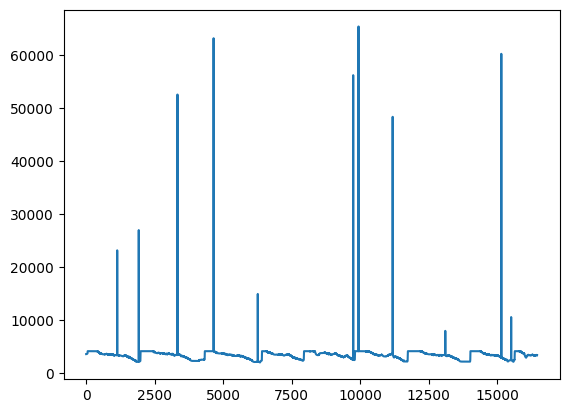

In [122]:
fs01_x_values=[]
fs02_x_values=[]

for i in range(0,fs01_count):
    fs01_x_values.append(i)
    
for i in range(0,fs02_count):
    fs02_x_values.append(i)

plt.plot(fs01_x_values,values_dates_fs01_ordered['value'])
#plt.plot(fs02_x_values,fs02_dec_value)

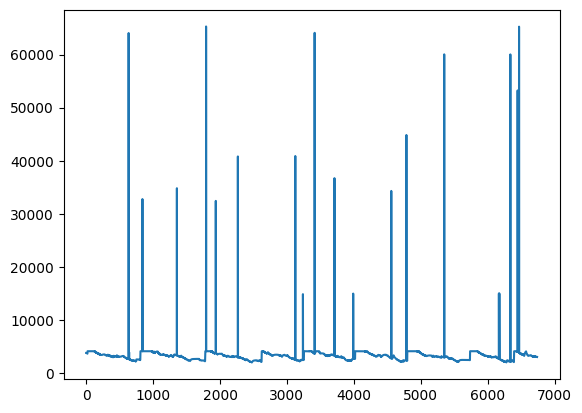

In [123]:
plt.plot(fs02_x_values,values_dates_fs02_ordered['value'])
#plt.plot(fs02_x_values,fs02_dec_value)

In [124]:
for i in range(0,values_dates_fs01.shape[0]):
    if int(values_dates_fs01.iloc[i,0])>4095:
        print(values_dates_fs01.iloc[i,2],values_dates_fs01.iloc[i,0])

0x2525210022063F086948706018799326091715325300013E0107826F5AFFBFBACBFF 23151
0x25252100220A93086948706018799326091916254800013E01FF195D698F695E9CC6 26973
0x25252100221258086948706018799326092316115400013E01071A6FCDCF74CA2D39 52591
0x25252100201994086948706018799326092506413701013E01071FFFF6FF8467 63231
0x25252100222273086948706018799326092816251600013E0107FA3A3ADF9B6A8AFF 14906
0x2525210022359C086948706018799326100516563700013E01F71BBADBEEBBEBA719 56250
0x252521002036AE086948706018799326100615461500013E010719AFFFE8FF35 65455
0x25252100223D82086948706018799326100812000601013E01071BFDBCDD0A93AC6F 48381
0x2525210022480E086948706018799326101315501101013E01071CFD1EFBEF9ED2FF 7933
0x25252100225351086948706018799326101614101701013E01F71F7EEBC2FF7733FE 60286
0x2525210021554A086948706018799326101717054000013E0112072B29B7DBD8F0 10539


In [125]:
for i in range(0,values_dates_fs02.shape[0]):
    if int(values_dates_fs02.iloc[i,0])>4095:
        print(values_dates_fs01.iloc[i,2],values_dates_fs02.iloc[i,0])

0x25252100200380086948706018799326091613044800013E01071AA90D91DA38 64058
0x252521002004A3086948706018799326091619052001013E01071E800D07D811 32767
0x25252100200775086948706018799326091722012500013E01071C4D0CD6C43F 34811
0x252521002009DC086948706018799326091820410101013E01071F1B09BF9199 65295
0x25252100200AA9086948706018799326091916534901013E010718610819868A 32424
0x25252100200C79086948706018799326092122440601013E01071CFF0FFFFFA0 40799
0x25252100201131086948706018799326092223421601013E01071EC60D65DC52 40880
0x252521002011D1086948706018799326092313183800013E010717EB0CBACE86 14847
0x252521002012C7086948706018799326092318315501013E01071D530D3BD54B 64096
0x25252100201468086948706018799326092403081301013E01071EB70A75AB98 36707
0x252521002015F3086948706018799326092411181600013E01071BC208278C6A 14954
0x25252100201912086948706018799326092503585101013E01071DFF0FFFFF6D 34300
0x25252100201A4E086948706018799326092510430901013E01071CB00E04EB37 44843
0x25252100201D69086948706018799326092611073001013E0

FS01:
9805,2488,261005183438,0x252521002035EA086948706018799326100518343800013E01071BB8098D9B65
9806,2498,261005183623,0x252521002035EB086948706018799326100518362300013E01071BC2092C9C7F
9807,2514,261005183808,0x252521002035EC086948706018799326100518380800013E01071BD209299DE6
9808,2535,261005183953,0x252521002035EE086948706018799326100518395300013E01071BE709709E08
9809,2558,261005184138,0x252521002035EF086948706018799326100518413800013E01071BFE09E89F48
9810,2659,261005184323,0x252521002035F1086948706018799326100518432300013E01071B630A3EA600
9811,3058,261005184508,0x252521002035F2086948706018799326100518450800013E01071BF20B29BF46
9812,3435,261005184653,0x252521002035F3086948706018799326100518465300013E01071B6B0DB6D6C7
9813,3809,261005184838,0x252521002035F5086948706018799326100518483800013E01071BE10E12EE48
9814,4095,261005185023,0x252521002035F6086948706018799326100518502300013E01071BFF0FFFFFF1

FS02:
9807,2514,261005183808,0x252521002035EC086948706018799326100518380800013E01071BD209299DE6
9808,2535,261005183953,0x252521002035EE086948706018799326100518395300013E01071BE709709E08
9809,2558,261005184138,0x252521002035EF086948706018799326100518413800013E01071BFE09E89F48
9810,2659,261005184323,0x252521002035F1086948706018799326100518432300013E01071B630A3EA600
9811,3058,261005184508,0x252521002035F2086948706018799326100518450800013E01071BF20B29BF46
9812,3435,261005184653,0x252521002035F3086948706018799326100518465300013E01071B6B0DB6D6C7
9813,3809,261005184838,0x252521002035F5086948706018799326100518483800013E01071BE10E12EE48
9814,4095,261005185023,0x252521002035F6086948706018799326100518502300013E01071BFF0FFFFFF1

In [126]:
gallons_fs01=[] #Editable
gallons_fs02=[] #Editable
m1=0.0836       #Editable
b1=0.3113      #Editable
m2=0.0836       #Editable
b2=0.3113       #Editable

values_dates_fs01_ordered.info()

for i in range(0,values_dates_fs01_ordered.shape[0]):
    gallons_value_fs01=(float(values_dates_fs01_ordered.iloc[i,0]*m1-b1)/3.785412)
    gallons_fs01.append(gallons_value_fs01) 
    #print(i,values_dates_fs01_ordered.iloc[i,2][32:44],(values_dates_fs01_ordered.iloc[i,0]*m1-b1)/3.785412)

for i in range(0,values_dates_fs02_ordered.shape[0]):
    gallons_value_fs02=(float(values_dates_fs02_ordered.iloc[i,0]*m2-b2)/3.785412)
    gallons_fs02.append(gallons_value_fs02)  
    #print(i,values_dates_fs02_ordered.iloc[i,2][32:44],(values_dates_fs02_ordered.iloc[i,0]*m1-b1)/3.785412)

values_dates_fs01_ordered['gallons']=gallons_fs01
values_dates_fs02_ordered['gallons']=gallons_fs02

<class 'pandas.DataFrame'>
Index: 16462 entries, 0 to 16461
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   value     16462 non-null  int64
 1   date      16462 non-null  str  
 2   raw data  16462 non-null  str  
dtypes: int64(1), str(2)
memory usage: 514.4 KB


In [127]:
capacity_1=90       #Editable
capacity_2=90       #Editable
level=0
p=0 # If vahice is parked, p=0

date1=261005183808  #Editable
date2=261005185023  #Editable

print("Tank 1: ")
print("Raising/Droping","->","end gallons","->","initial gallons","->","new_delta + old_delta")
for i in range(0,values_dates_fs01_ordered.shape[0]):
    if int(values_dates_fs01_ordered.iloc[i,1])>=date1 and int(values_dates_fs01_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs01_ordered.iloc[i+1,3]>=(values_dates_fs01_ordered.iloc[i,3]+(p/100)*capacity_1):
            level=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]+level
            print("raising",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level)
        if values_dates_fs01_ordered.iloc[i+1,3]<=(values_dates_fs01_ordered.iloc[i,3]-(p/100)*capacity_1):
            level=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]+level
            print("droping",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level)
print("Level change tank 1: ",level)

print("Level change tank 1 + Level change tank 2: ")
for i in range(0,values_dates_fs02_ordered.shape[0]):
    if int(values_dates_fs02_ordered.iloc[i,1])>=date1 and int(values_dates_fs02_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs02_ordered.iloc[i+1,3]>=(values_dates_fs02_ordered.iloc[i,3]+(p/100)*capacity_2):
            level=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]+level
            print("raising",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level)
        if values_dates_fs02_ordered.iloc[i+1,3]<=(values_dates_fs02_ordered.iloc[i,3]-(p/100)*capacity_2):
            level=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]+level
            print("droping",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level)

print("Level change toal: ",level)

Tank 1: 
Raising/Droping -> end gallons -> initial gallons -> new_delta + old_delta
raising 55.90268641828155 55.43890598962543 0.4637804286561149
raising 56.41063641157158 55.90268641828155 0.9717304219461482
raising 58.64119942558432 56.41063641157158 3.202293435958886
raising 67.4530275700505 58.64119942558432 12.014121580425062
raising 75.7789905035436 67.4530275700505 20.340084513918164
raising 84.03869909008583 75.7789905035436 28.599793100460396
raising 90.35494683273576 84.03869909008583 34.91604084311033
raising 90.35494683273576 90.35494683273576 34.91604084311033
droping 90.35494683273576 90.35494683273576 34.91604084311033
Level change tank 1:  34.91604084311033
Level change tank 1 + Level change tank 2: 
raising 90.35494683273576 85.45212515837112 39.818862517474976
raising 90.35494683273576 90.35494683273576 39.818862517474976
droping 90.35494683273576 90.35494683273576 39.818862517474976
raising 90.35494683273576 90.35494683273576 39.818862517474976
droping 90.3549468327

Adding the validation to delete the value that beongs to ragistger i+1.

In [128]:
print("Tank 1: ")
print("Raising/Droping","->","end gallons","->","initial gallons","->","new_delta + old_delta","->","delta")
for i in range(0,values_dates_fs01_ordered.shape[0]):
    if int(values_dates_fs01_ordered.iloc[i,1])>=date1 and int(values_dates_fs01_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs01_ordered.iloc[i+1,3]>(values_dates_fs01_ordered.iloc[i,3]+(p/100)*capacity_1):
            level=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]+level
            print("raising",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level,values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3])
        if values_dates_fs01_ordered.iloc[i+1,3]<(values_dates_fs01_ordered.iloc[i,3]-(p/100)*capacity_1):
            level=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]+level
            print("droping",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level,values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3])
        if int(values_dates_fs01_ordered.iloc[i+1,1])>date2:
            level=level-float(values_dates_fs01_ordered.iloc[i+1,3]-float(values_dates_fs01_ordered.iloc[i,3]))
print("Level change tank 1: ",level)

print("Level change tank 1 + Level change tank 2: ")
for i in range(0,values_dates_fs02_ordered.shape[0]):
    if int(values_dates_fs02_ordered.iloc[i,1])>=date1 and int(values_dates_fs02_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs02_ordered.iloc[i+1,3]>(values_dates_fs02_ordered.iloc[i,3]+(p/100)*capacity_2):
            level=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]+level
            print("raising",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level,values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs02_ordered.iloc[i+1,3]<(values_dates_fs02_ordered.iloc[i,3]-(p/100)*capacity_2):
            level=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]+level
            print("droping",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level,values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3])
        if int(values_dates_fs02_ordered.iloc[i+1,1])>date2:
            level=level-float(values_dates_fs02_ordered.iloc[i+1,3]-float(values_dates_fs02_ordered.iloc[i,3]))

print("Level change toal: ",level)

Tank 1: 
Raising/Droping -> end gallons -> initial gallons -> new_delta + old_delta -> delta
raising 55.90268641828155 55.43890598962543 40.28264294613109 0.4637804286561149
raising 56.41063641157158 55.90268641828155 40.790592939421124 0.5079499932900333
raising 58.64119942558432 56.41063641157158 43.02115595343386 2.2305630140127377
raising 67.4530275700505 58.64119942558432 51.83298409790004 8.811828144466176
raising 75.7789905035436 67.4530275700505 60.15894703139314 8.325962933493102
raising 84.03869909008583 75.7789905035436 68.41865561793537 8.259708586542232
raising 90.35494683273576 84.03869909008583 74.7349033605853 6.316247742649935
Level change tank 1:  74.7349033605853
Level change tank 1 + Level change tank 2: 
raising 90.35494683273576 85.45212515837112 79.63772503494995 4.902821674364645
Level change toal:  79.63772503494995


In [129]:
print("Tank 1: ")
print("Raising/Droping","->","end gallons","->","initial gallons","->","new_delta + old_delta","->","delta")
for i in range(0,values_dates_fs01_ordered.shape[0]):
    if int(values_dates_fs01_ordered.iloc[i,1])>=date1 and int(values_dates_fs01_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs01_ordered.iloc[i+1,3]>(values_dates_fs01_ordered.iloc[i,3]+(p/100)*capacity_1):
            delta=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]
            level=delta+level
            print("raising",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level,values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3])
        if values_dates_fs01_ordered.iloc[i+1,3]<(values_dates_fs01_ordered.iloc[i,3]-(p/100)*capacity_1):
            delta=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]
            level=delta+level
            print("droping",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level,values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3])
        if int(values_dates_fs01_ordered.iloc[i+1,1])>date2:
            level=level-float(values_dates_fs01_ordered.iloc[i+1,3]-float(values_dates_fs01_ordered.iloc[i,3]))
print("Level change tank 1: ",level)

print("Level change tank 1 + Level change tank 2: ")
for i in range(0,values_dates_fs02_ordered.shape[0]):
    if int(values_dates_fs02_ordered.iloc[i,1])>=date1 and int(values_dates_fs02_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs02_ordered.iloc[i+1,3]>(values_dates_fs02_ordered.iloc[i,3]+(p/100)*capacity_2):
            delta=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]
            level=delta+level
            print("raising",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level,delta)
        if values_dates_fs02_ordered.iloc[i+1,3]<(values_dates_fs02_ordered.iloc[i,3]-(p/100)*capacity_2):
            delta=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]
            level=delta+level
            print("droping",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level,delta)
        if int(values_dates_fs02_ordered.iloc[i+1,1])>date2:
            level=level-float(values_dates_fs02_ordered.iloc[i+1,3]-float(values_dates_fs02_ordered.iloc[i,3]))

print("Level change toal: ",level)

Tank 1: 
Raising/Droping -> end gallons -> initial gallons -> new_delta + old_delta -> delta
raising 55.90268641828155 55.43890598962543 80.10150546360606 0.4637804286561149
raising 56.41063641157158 55.90268641828155 80.60945545689609 0.5079499932900333
raising 58.64119942558432 56.41063641157158 82.84001847090883 2.2305630140127377
raising 67.4530275700505 58.64119942558432 91.651846615375 8.811828144466176
raising 75.7789905035436 67.4530275700505 99.97780954886811 8.325962933493102
raising 84.03869909008583 75.7789905035436 108.23751813541034 8.259708586542232
raising 90.35494683273576 84.03869909008583 114.55376587806028 6.316247742649935
Level change tank 1:  114.55376587806028
Level change tank 1 + Level change tank 2: 
raising 90.35494683273576 85.45212515837112 119.45658755242492 4.902821674364645
Level change toal:  119.45658755242492


Create a report as dataframe

In [130]:
delta_aux=[]
x_after=[]
x_=[]

df_report=pd.DataFrame()

print("Tank 1: ")
print("Raising/Droping","->","end gallons","->","initial gallons","->","new_delta + old_delta","->","delta")
for i in range(0,values_dates_fs01_ordered.shape[0]):
    if int(values_dates_fs01_ordered.iloc[i,1])>=date1 and int(values_dates_fs01_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs01_ordered.iloc[i+1,3]>(values_dates_fs01_ordered.iloc[i,3]+(p/100)*capacity_1):            
            delta=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]
            delta_aux.append(delta)
            x_after.append(values_dates_fs01_ordered.iloc[i+1,3])
            x_.append(values_dates_fs01_ordered.iloc[i,3])
            level=delta+level
            print("raising",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level,values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3])
        if values_dates_fs01_ordered.iloc[i+1,3]<(values_dates_fs01_ordered.iloc[i,3]-(p/100)*capacity_1):
            delta=values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3]
            delta_aux.append(delta)
            x_after.append(values_dates_fs01_ordered.iloc[i+1,3])
            x_.append(values_dates_fs01_ordered.iloc[i,3])
            level=delta+level
            print("droping",values_dates_fs01_ordered.iloc[i+1,3],values_dates_fs01_ordered.iloc[i,3],level,values_dates_fs01_ordered.iloc[i+1,3]-values_dates_fs01_ordered.iloc[i,3])
        if int(values_dates_fs01_ordered.iloc[i+1,1])>date2:
            level=level-float(values_dates_fs01_ordered.iloc[i+1,3]-float(values_dates_fs01_ordered.iloc[i,3]))
print("Level change tank 1: ",level)

print("Level change tank 1 + Level change tank 2: ")
for i in range(0,values_dates_fs02_ordered.shape[0]):
    if int(values_dates_fs02_ordered.iloc[i,1])>=date1 and int(values_dates_fs02_ordered.iloc[i,1])<=date2:
        #print(i,values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3])
        if values_dates_fs02_ordered.iloc[i+1,3]>(values_dates_fs02_ordered.iloc[i,3]+(p/100)*capacity_2):
            delta=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]
            delta_aux.append(delta)
            x_after.append(values_dates_fs01_ordered.iloc[i+1,3])
            x_.append(values_dates_fs01_ordered.iloc[i,3])
            level=delta+level
            print("raising",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level,delta)
        if values_dates_fs02_ordered.iloc[i+1,3]<(values_dates_fs02_ordered.iloc[i,3]-(p/100)*capacity_2):
            delta=values_dates_fs02_ordered.iloc[i+1,3]-values_dates_fs02_ordered.iloc[i,3]
            delta_aux.append(delta)
            x_after.append(values_dates_fs01_ordered.iloc[i+1,3])
            x_.append(values_dates_fs01_ordered.iloc[i,3])
            level=delta+level
            print("droping",values_dates_fs02_ordered.iloc[i+1,3],values_dates_fs02_ordered.iloc[i,3],level,delta)
        if int(values_dates_fs02_ordered.iloc[i+1,1])>date2:
            level=level-float(values_dates_fs02_ordered.iloc[i+1,3]-float(values_dates_fs02_ordered.iloc[i,3]))

df_report['x_']=x_
df_report['x_after']=x_after
df_report['delta']=delta_aux

df_report

Tank 1: 
Raising/Droping -> end gallons -> initial gallons -> new_delta + old_delta -> delta
raising 55.90268641828155 55.43890598962543 119.92036798108103 0.4637804286561149
raising 56.41063641157158 55.90268641828155 120.42831797437105 0.5079499932900333
raising 58.64119942558432 56.41063641157158 122.6588809883838 2.2305630140127377
raising 67.4530275700505 58.64119942558432 131.47070913284998 8.811828144466176
raising 75.7789905035436 67.4530275700505 139.7966720663431 8.325962933493102
raising 84.03869909008583 75.7789905035436 148.0563806528853 8.259708586542232
raising 90.35494683273576 84.03869909008583 154.37262839553523 6.316247742649935
Level change tank 1:  154.37262839553523
Level change tank 1 + Level change tank 2: 
raising 90.35494683273576 85.45212515837112 159.27545006989988 4.902821674364645


,x_,x_after,delta
0,55.438906,55.902686,0.463780
1,55.902686,56.410636,0.507950
2,56.410636,58.641199,2.230563
3,58.641199,67.453028,8.811828
4,67.453028,75.778991,8.325963
5,75.778991,84.038699,8.259709
6,84.038699,90.354947,6.316248
7,49.409760,49.409760,4.902822
